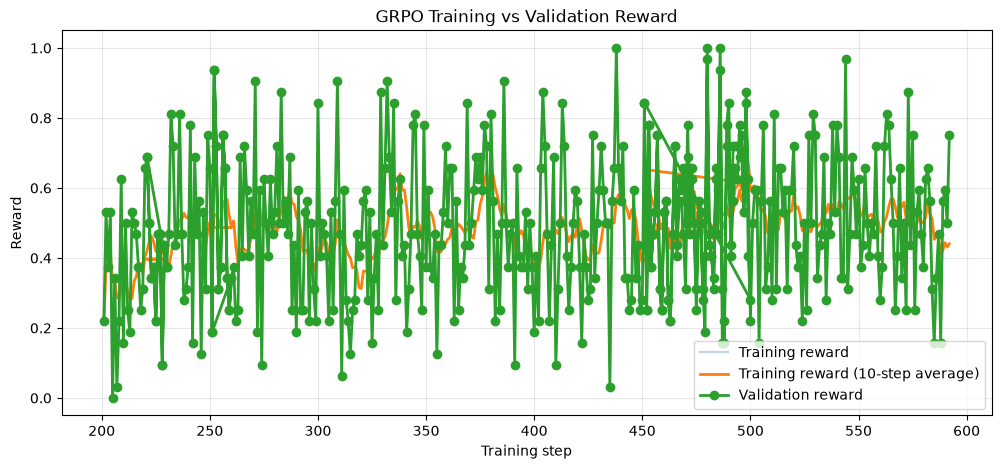


Validation results:
 step  reward  format_reward
  201 0.21875        0.93750
  202 0.53125        0.87500
  203 0.37500        0.93750
  204 0.53125        0.96875
  205 0.00000        0.87500
  206 0.34375        0.93750
  207 0.03125        0.93750
  208 0.21875        0.96875
  209 0.62500        0.96875
  210 0.15625        0.96875
  211 0.50000        1.00000
  212 0.25000        0.90625
  213 0.18750        0.87500
  214 0.53125        1.00000
  215 0.50000        0.90625
  216 0.46875        1.00000
  217 0.37500        1.00000
  218 0.25000        0.96875
  219 0.31250        0.90625
  220 0.65625        0.93750
  221 0.68750        0.96875
  222 0.50000        1.00000
  223 0.34375        1.00000
  224 0.37500        1.00000
  225 0.21875        1.00000
  226 0.46875        0.87500
  227 0.46875        1.00000
  228 0.09375        1.00000
  229 0.43750        1.00000
  230 0.37500        0.93750
  221 0.68750        0.96875
  222 0.50000        1.00000
  223 0.34375        1

In [104]:
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv("training_metrics_pad_fixed.csv")
val = pd.read_csv("training_metrics_pad_fixed.csv")

plt.figure(figsize=(12, 5))

plt.plot(train["step"], train["reward"], alpha=0.3, label="Training reward")
plt.plot(
    train["step"],
    train["reward"].rolling(window=10, min_periods=1).mean(),
    linewidth=2,
    label="Training reward (10-step average)"
)
plt.plot(
    val["step"], val["reward"],
    marker="o", linewidth=2, label="Validation reward"
)

plt.xlabel("Training step")
plt.ylabel("Reward")
plt.title("GRPO Training vs Validation Reward")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("\nValidation results:")
print(val[["step", "reward", "format_reward"]].to_string(index=False))

TRAINING LOG PROCESSING

Loading: training_metrics.csv
training_metrics.csv
  Total records: 251
  Internal duplicates removed: 0
  Unique records: 251

Loading: training_metrics_pad_fixed.csv
training_metrics_pad_fixed.csv
  Total records: 870
  Internal duplicates removed: 70
  Unique records: 800

VALIDATION LOG PROCESSING

Loading: validation_metrics.csv
validation_metrics.csv
  Total records: 3
  Internal duplicates removed: 0
  Unique records: 3

Loading: validation_metrics_pad_fixed.csv
validation_metrics_pad_fixed.csv
  Total records: 15
  Internal duplicates removed: 1
  Unique records: 14


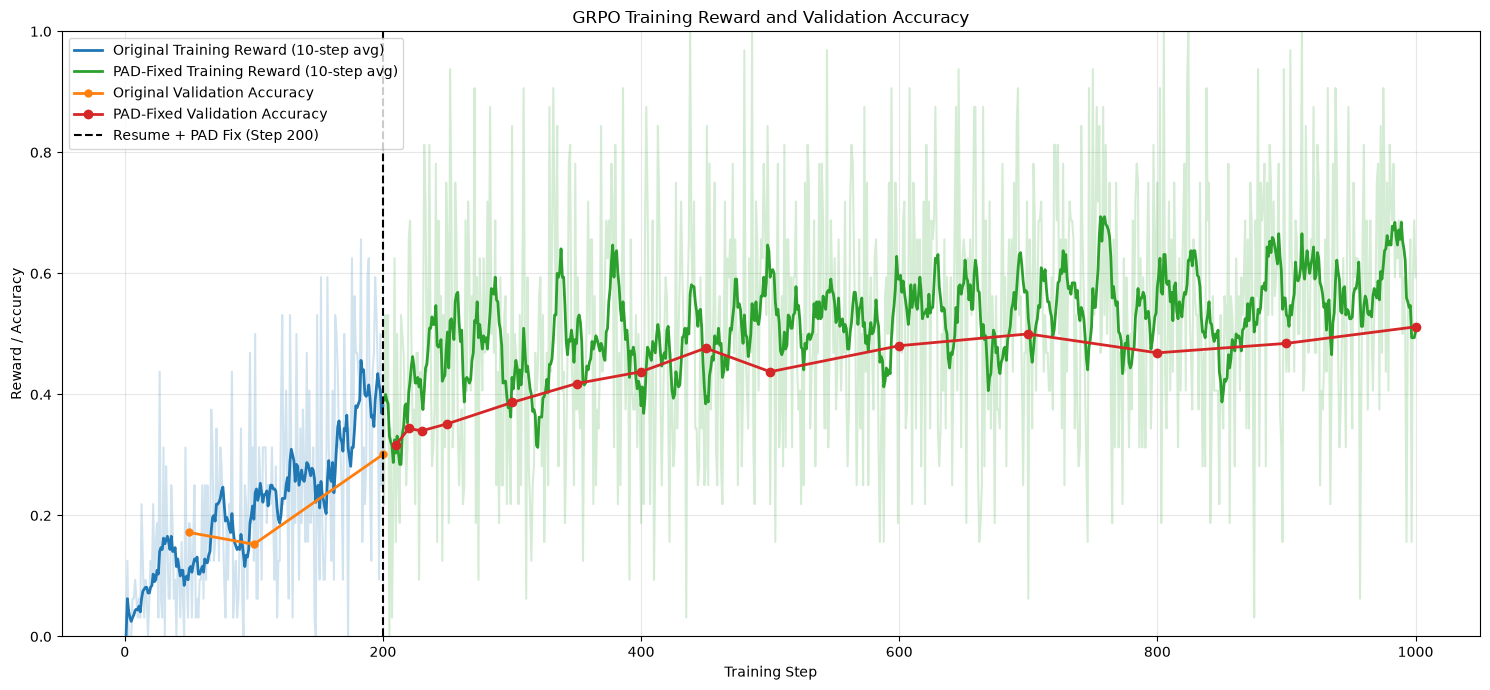


TRAINING LOGS
Original steps: 200
PAD-fixed steps: 800
Combined steps: 1000
Duplicate steps: 0
Training step range: 1 to 1000
Missing training steps: 0

VALIDATION LOGS
Original validation records: 3
PAD-fixed validation records: 14
Combined validation records: 17
Duplicate steps: 0

VALIDATION HISTORY
 step  accuracy   reward  format_reward
   50  0.171875 0.171875       0.933594
  100  0.152344 0.152344       0.996094
  200  0.300781 0.300781       0.992188
  210  0.316406 0.316406       1.000000
  220  0.343750 0.343750       1.000000
  230  0.339844 0.339844       0.988281
  250  0.351562 0.351562       0.988281
  300  0.386719 0.386719       0.984375
  350  0.417969 0.417969       0.953125
  400  0.437500 0.437500       0.859375
  450  0.476562 0.476562       0.980469
  500  0.437500 0.437500       0.984375
  600  0.480469 0.480469       0.964844
  700  0.500000 0.500000       0.976562
  800  0.468750 0.468750       0.949219
  900  0.484375 0.484375       0.933594
 1000  0.511719

In [131]:

import pandas as pd
import matplotlib.pyplot as plt


TRAIN_ORIGINAL = "training_metrics.csv"
TRAIN_FIXED = "training_metrics_pad_fixed.csv"

VAL_ORIGINAL = "validation_metrics.csv"
VAL_FIXED = "validation_metrics_pad_fixed.csv"

RESUME_STEP = 200
SMOOTH_WINDOW = 10


def load_and_clean(path):
    df = pd.read_csv(path)

    # Ensure step is numeric
    df["step"] = pd.to_numeric(df["step"], errors="coerce")

    # Remove invalid steps
    df = df.dropna(subset=["step"]).copy()
    df["step"] = df["step"].astype(int)

    before = len(df)

    df = df.drop_duplicates(subset=["step"], keep="last")

    removed = before - len(df)

    df = df.sort_values("step").reset_index(drop=True)

    print(f"{path}")
    print(f"  Total records: {before}")
    print(f"  Internal duplicates removed: {removed}")
    print(f"  Unique records: {len(df)}")

    return df


def combine_logs(original_path, fixed_path, resume_step=200):

    print("\nLoading:", original_path)
    original = load_and_clean(original_path)

    print("\nLoading:", fixed_path)
    fixed = load_and_clean(fixed_path)

    # Original run contributes steps 0 through 200
    original = original[
        original["step"] <= resume_step
    ].copy()

    # PAD-fixed run contributes steps after 200
    fixed = fixed[
        fixed["step"] > resume_step
    ].copy()

    # Combine both runs
    combined = pd.concat(
        [original, fixed],
        ignore_index=True
    )

    # Extra protection against duplicate steps
    combined = (
        combined
        .drop_duplicates(subset=["step"], keep="last")
        .sort_values("step")
        .reset_index(drop=True)
    )

    original = original.reset_index(drop=True)
    fixed = fixed.reset_index(drop=True)

    return original, fixed, combined

print("=" * 60)
print("TRAINING LOG PROCESSING")
print("=" * 60)

train_original, train_fixed, train_combined = combine_logs(
    TRAIN_ORIGINAL,
    TRAIN_FIXED,
    RESUME_STEP
)

print("\n" + "=" * 60)
print("VALIDATION LOG PROCESSING")
print("=" * 60)

val_original, val_fixed, val_combined = combine_logs(
    VAL_ORIGINAL,
    VAL_FIXED,
    RESUME_STEP
)

train_combined["smooth_reward"] = (
    train_combined["reward"]
    .rolling(
        window=SMOOTH_WINDOW,
        min_periods=1
    )
    .mean()
)

# Split the smoothed data for original plot colors
train_original = train_combined[
    train_combined["step"] <= RESUME_STEP
].copy()

train_fixed = train_combined[
    train_combined["step"] > RESUME_STEP
].copy()

fig, ax = plt.subplots(figsize=(15, 7))

ax.plot(
    train_original["step"],
    train_original["reward"],
    color="tab:blue",
    alpha=0.2,
)

ax.plot(
    train_original["step"],
    train_original["smooth_reward"],
    color="tab:blue",
    linewidth=2,
    label=f"Original Training Reward ({SMOOTH_WINDOW}-step avg)",
)

ax.plot(
    train_fixed["step"],
    train_fixed["reward"],
    color="tab:green",
    alpha=0.2,
)

ax.plot(
    train_fixed["step"],
    train_fixed["smooth_reward"],
    color="tab:green",
    linewidth=2,
    label=f"PAD-Fixed Training Reward ({SMOOTH_WINDOW}-step avg)",
)

ax.plot(
    val_original["step"],
    val_original["accuracy"],
    color="tab:orange",
    marker="o",
    markersize=5,
    linewidth=2,
    label="Original Validation Accuracy",
)

ax.plot(
    val_fixed["step"],
    val_fixed["accuracy"],
    color="tab:red",
    marker="o",
    markersize=6,
    linewidth=2,
    label="PAD-Fixed Validation Accuracy",
)

ax.axvline(
    RESUME_STEP,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Resume + PAD Fix (Step {RESUME_STEP})",
)


ax.set_xlabel("Training Step")
ax.set_ylabel("Reward / Accuracy")

ax.set_title(
    "GRPO Training Reward and Validation Accuracy"
)

ax.set_ylim(0, 1)

ax.grid(alpha=0.3)

ax.legend()

plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("TRAINING LOGS")
print("=" * 60)

print("Original steps:", len(train_original))
print("PAD-fixed steps:", len(train_fixed))
print("Combined steps:", len(train_combined))

print(
    "Duplicate steps:",
    train_combined["step"].duplicated().sum()
)

print(
    "Training step range:",
    train_combined["step"].min(),
    "to",
    train_combined["step"].max()
)

# Detect missing steps in the combined training history
expected_steps = set(
    range(
        int(train_combined["step"].min()),
        int(train_combined["step"].max()) + 1
    )
)

actual_steps = set(train_combined["step"])

missing_steps = sorted(expected_steps - actual_steps)

print("Missing training steps:", len(missing_steps))

if missing_steps:
    print("Missing step numbers:", missing_steps[:50])


print("\n" + "=" * 60)
print("VALIDATION LOGS")
print("=" * 60)

print("Original validation records:", len(val_original))
print("PAD-fixed validation records:", len(val_fixed))
print("Combined validation records:", len(val_combined))

print(
    "Duplicate steps:",
    val_combined["step"].duplicated().sum()
)

print("\n" + "=" * 60)
print("VALIDATION HISTORY")
print("=" * 60)

print(
    val_combined[
        ["step", "accuracy", "reward", "format_reward"]
    ].to_string(index=False)
)

train_combined.to_csv(
    "training_metrics_combined.csv",
    index=False
)

val_combined.to_csv(
    "validation_metrics_combined.csv",
    index=False
)

print("\n" + "=" * 60)
print("SAVED CLEANED LOGS")
print("=" * 60)

print("training_metrics_combined.csv")
print("validation_metrics_combined.csv")


In [129]:
import os
import shutil

path = "/workspace/LLM-1b-lab"

total, used, free = shutil.disk_usage(path)

print("=" * 55)
print("DISK STORAGE")
print("=" * 55)
print(f"Total: {total / 1024**3:.2f} GB")
print(f"Used:  {used / 1024**3:.2f} GB")
print(f"Free:  {free / 1024**3:.2f} GB")

print("\n" + "=" * 55)
print("CHECKPOINT DIRECTORY SIZES")
print("=" * 55)

for directory in [
    "checkpoints",
    "checkpoints_pad_fixed",
]:
    if not os.path.exists(directory):
        continue

    for name in sorted(os.listdir(directory)):
        full_path = os.path.join(directory, name)

        if os.path.isdir(full_path):
            size = sum(
                os.path.getsize(os.path.join(root, file))
                for root, _, files in os.walk(full_path)
                for file in files
            )
            print(f"{full_path}: {size / 1024**3:.2f} GB")

DISK STORAGE
Total: 100.00 GB
Used:  89.72 GB
Free:  10.28 GB

CHECKPOINT DIRECTORY SIZES
checkpoints_pad_fixed/step_1000: 15.73 GB
checkpoints_pad_fixed/step_700: 16.60 GB
checkpoints_pad_fixed/step_800: 16.60 GB
checkpoints_pad_fixed/step_900: 16.60 GB


In [113]:
!rm -rf checkpoints_pad_fixed/step_500